#Data Collection

import file

In [1]:
!curl -L -o ./higher-education-predictors-of-student-retention.zip https://www.kaggle.com/api/v1/datasets/download/thedevastator/higher-education-predictors-of-student-retention

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 89332  100 89332    0     0   222k      0 --:--:-- --:--:-- --:--:--  222k


unzip file

In [2]:
!unzip ./higher-education-predictors-of-student-retention.zip

Archive:  ./higher-education-predictors-of-student-retention.zip
  inflating: dataset.csv             


Creat Data frame

In [3]:
import pandas as pd
df = pd.read_csv("./dataset.csv")


vizualize data frame

In [4]:
df = pd.read_csv("./dataset.csv")

In [5]:
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,12,1,17,0,12,1,22,27,10,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,12,1,1,1,13,28,8,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,9,4,11,1,1,1,22,27,10,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,10,1,1,15,1,1,10,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,10,1,1,1,1,14,5,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


# PreProcessing

##import library

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

##check null values

In [7]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


handle null values

In [8]:
df = df.dropna()


##check duplicate values

In [9]:
df.duplicated().sum()

np.int64(0)

handle duplicate value

In [10]:
df = df.drop_duplicates()


##Target Preprocessing (Nakkavita N.K.P.P - IT24100244)

drop row values = "Enrolled"

In [11]:
df = df[df["Target"] != "Enrolled"]
df["Target"].value_counts()


,count
Target,
Graduate,2209
Dropout,1421


Distribution of Target after Dropping

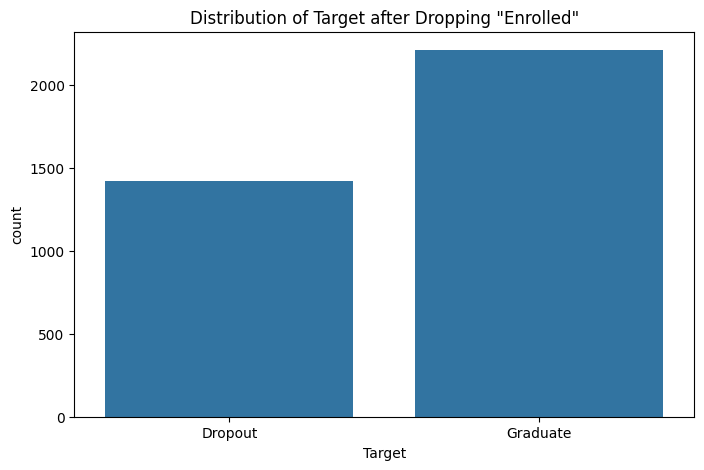

In [12]:
# Count plot
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Target')
plt.title('Distribution of Target after Dropping "Enrolled"')
plt.show()

##Encode categorical Variables (Jayaratne M. Y. De S. - IT24100284)

Encode the target columns Dropout=1 and graduate=0

In [13]:
df["Target"] = df["Target"].map({"Dropout": 1, "Graduate": 0})
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,1
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,0
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,1
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,0
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,0


percentage of each category

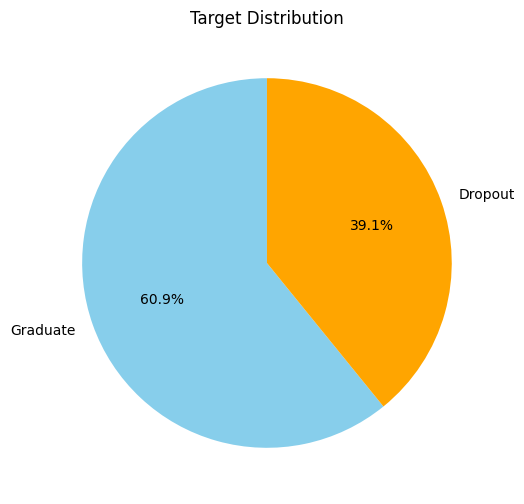

In [14]:
counts = df['Target'].value_counts()
labels = ['Graduate', 'Dropout']

plt.figure(figsize=(6,6))
plt.pie(counts, labels=labels, autopct='%1.1f%%', colors=['skyblue','orange'], startangle=90)
plt.title('Target Distribution')
plt.show()


##outlier Detection (Vinranga M. W. S. - IT24100374)

custom outlier remove for get value betweeen 0-20

In [15]:
# List of your curricular columns
curricular_cols = [
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
]

for col in curricular_cols:
    # Keep only rows where value is between 0 and 20 (inclusive)
    df = df[(df[col] >= 0) & (df[col] <= 20)]

Normal outlier remove

In [16]:
numeric_cols = ['Age at enrollment','Unemployment rate','Inflation rate', 'GDP']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Remove outliers
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    df_outlier_removed = df.copy()

Boxplot After remove outliers

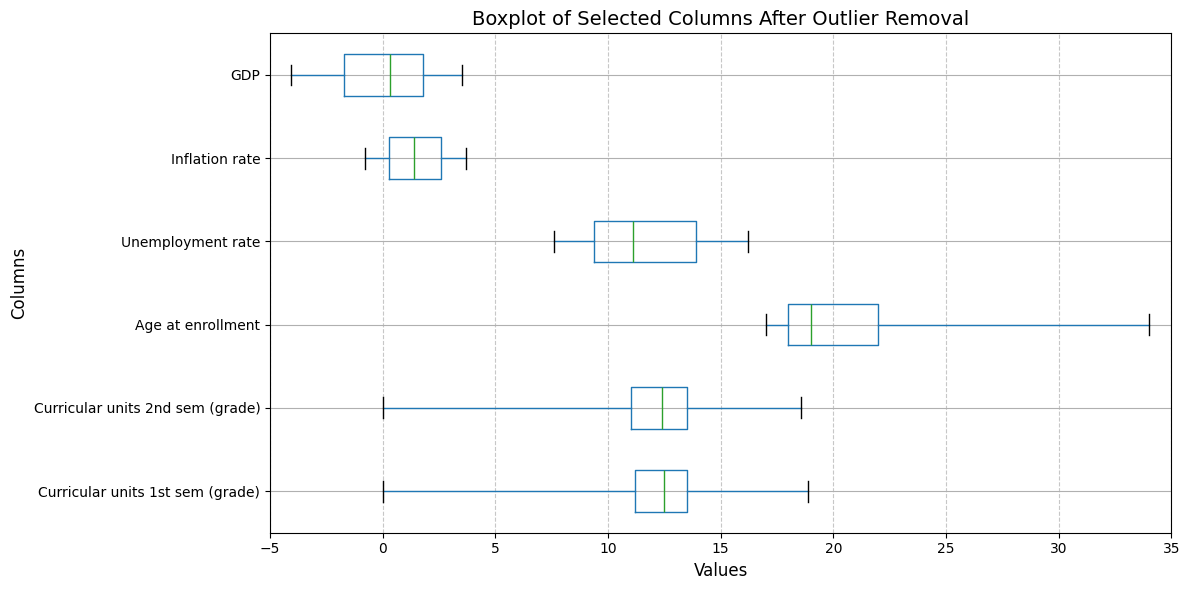

In [17]:
# Selected columns
selected_cols = [
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)',
    'Age at enrollment',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

plt.figure(figsize=(12, 6))

# Use whis=[0,100] to extend whiskers to min/max and avoid extra outlier dots
df[selected_cols].boxplot(vert=False, whis=[0, 100])

plt.title("Boxplot of Selected Columns After Outlier Removal", fontsize=14)
plt.xlabel("Values", fontsize=12)
plt.ylabel("Columns", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xlim(-5, 35)
plt.tight_layout()
plt.show()



##Feature Scaling (Faazil M.M.M  - IT24100363)

In [18]:
from sklearn.preprocessing import StandardScaler

numeric_cols_to_scale = [
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP',
    'Age at enrollment'
]

scaler = StandardScaler()

df[numeric_cols_to_scale] = scaler.fit_transform(df[numeric_cols_to_scale])

In [19]:
df.head(10)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,-0.268806,-2.813848,-1.980450,-1.509342,-1.918718,-0.182246,-0.303683,0.126968,0.763116,1
1,1,6,1,11,1,1,1,1,3,4,...,-0.268806,-0.118641,-0.444891,0.452076,0.635676,-0.182246,0.867578,-1.104425,0.340296,0
2,1,1,5,5,1,1,1,22,27,10,...,-0.268806,-0.118641,-1.980450,-1.509342,-1.918718,-0.182246,-0.303683,0.126968,0.763116,1
3,1,8,2,15,1,1,1,23,27,6,...,-0.268806,-0.118641,0.578816,0.125173,0.398928,-0.182246,-0.832640,-1.466599,-1.399944,0
6,1,1,1,12,1,1,1,13,28,8,...,-0.268806,0.779761,0.066963,1.105882,0.762462,-0.182246,1.472100,1.141056,-1.818314,0
7,1,9,4,11,1,1,1,22,27,10,...,-0.268806,-0.567842,-0.700817,-1.509342,-1.918718,-0.182246,1.472100,1.141056,-1.818314,1
8,1,1,3,10,1,1,15,1,1,10,...,-0.268806,-0.118641,-0.188964,0.452076,0.724680,-0.182246,1.736578,-0.669816,-0.420781,0
9,1,1,1,10,1,1,1,1,14,5,...,-0.268806,-0.118641,1.602522,-0.855536,0.604525,-0.182246,-1.021553,0.126968,1.550897,1
10,1,1,1,14,1,1,1,23,14,6,...,-0.268806,-0.118641,-0.188964,0.125173,0.735360,-0.182246,0.867578,-1.104425,0.340296,0
11,1,1,1,12,1,1,1,13,28,10,...,-0.268806,0.779761,0.066963,0.778979,0.551123,-0.182246,0.414187,1.792969,-0.767939,0


save for future use when give new data

In [20]:
import joblib
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']

histrograms after scaling

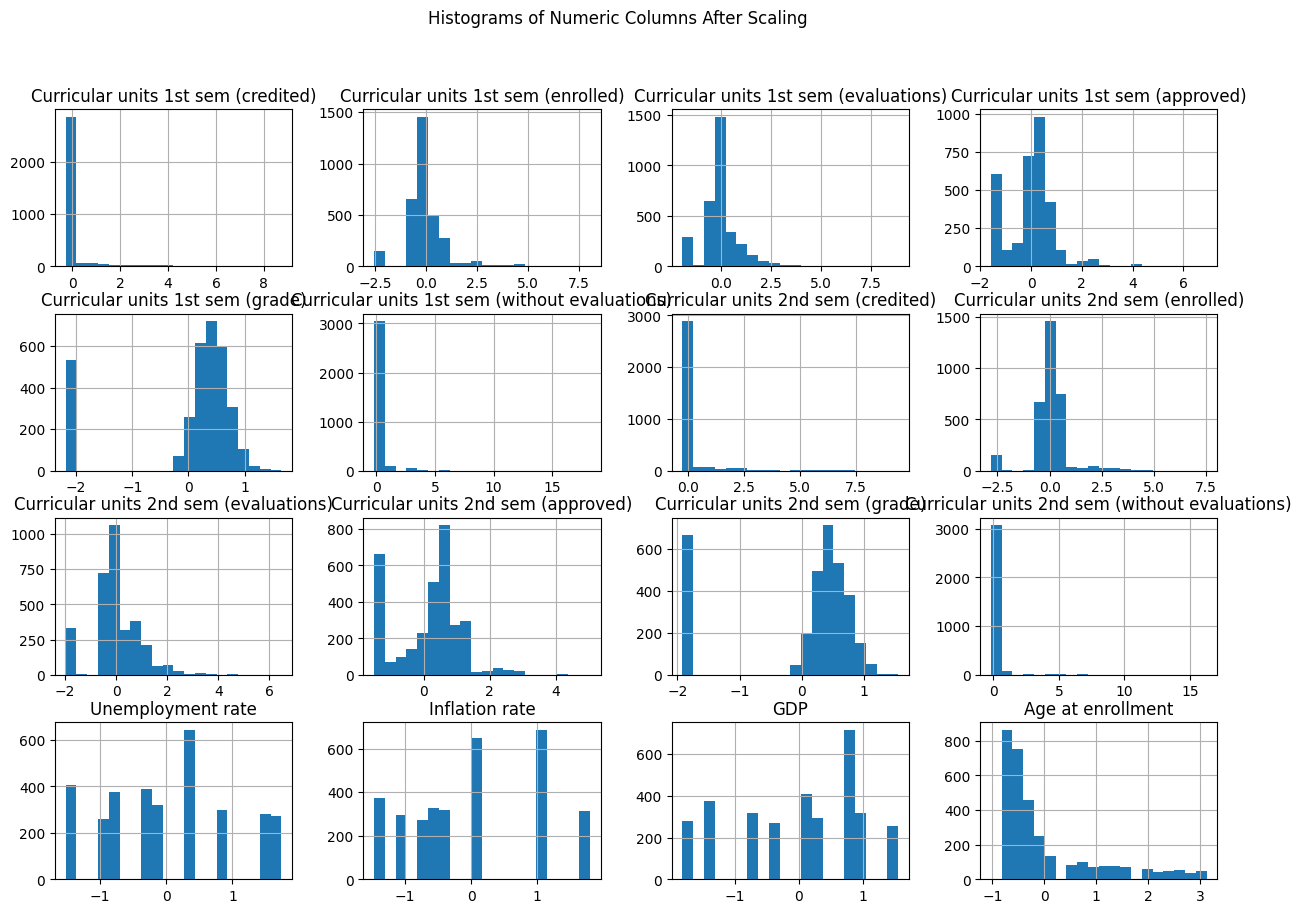

In [21]:
df[numeric_cols_to_scale].hist(bins=20, figsize=(15,10))
plt.suptitle("Histograms of Numeric Columns After Scaling")
plt.show()


##Balance Target column (Dissanayaka A.D.M.N.K. - IT24100225)

View colum count

In [22]:
df["Target"].value_counts()

,count
Target,
0,2057
1,1184


over sampling

In [23]:
from sklearn.utils import resample
# Separate classes
df_majority = df[df["Target"] == 0]
df_minority = df[df["Target"] == 1]

# Upsample minority class (1)
df_minority_upsampled = resample(
    df_minority,
    replace=True,
    n_samples=len(df_majority),
    random_state=42
)

# Combine majority class with upsampled minority
df_balanced = pd.concat([df_majority, df_minority_upsampled])

# Shuffle dataset
df_balanced = df_balanced.sample(frac=1, random_state=42).reset_index(drop=True)

# Check new class distribution
print(df_balanced['Target'].value_counts())


Target
0    2057
1    2057
Name: count, dtype: int64


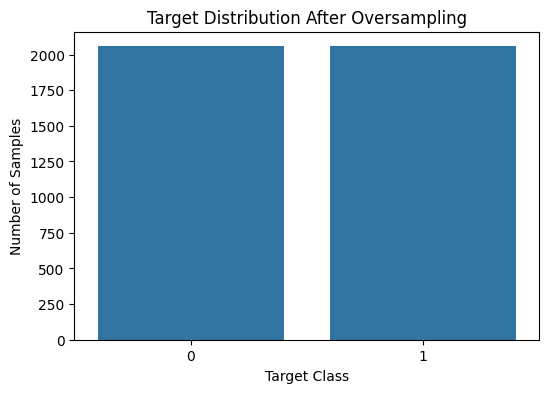

In [24]:
plt.figure(figsize=(6,4))
sns.countplot(x='Target', data=df_balanced)
plt.title("Target Distribution After Oversampling")
plt.xlabel("Target Class")
plt.ylabel("Number of Samples")
plt.show()





##Feature Selection (Weerasingha P. M. P. L. - IT24100316)

Correlation check

In [25]:
# Numeric features only
X_num = df_balanced[numeric_cols_to_scale]
y = df_balanced['Target']

# Add target as column to compute correlation
df_corr = X_num.copy()
df_corr['Target'] = y

# Pearson correlation
corr_matrix = df_corr.corr()
target_corr = corr_matrix['Target'].drop('Target')

# Select top 10 features by absolute correlation
top_numeric_features = target_corr.abs().sort_values(ascending=False).head(10).index
print("Top numeric features by correlation:", top_numeric_features)


Top numeric features by correlation: Index(['Curricular units 2nd sem (approved)',
       'Curricular units 2nd sem (grade)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)', 'Age at enrollment',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (without evaluations)',
       'Curricular units 1st sem (without evaluations)'],
      dtype='object')


find catagorical columns

In [26]:
# All columns in dataframe except numeric columns and target
categorical_encoded_cols = [col for col in df_balanced.columns
                            if col not in numeric_cols_to_scale + ['Target']]

print("Categorical columns for encoding / Chi-Square:", categorical_encoded_cols)


Categorical columns for encoding / Chi-Square: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']


chi squre test

In [27]:

from sklearn.feature_selection import SelectKBest, chi2

X_cat = df_balanced[categorical_encoded_cols]
y = df_balanced['Target']

chi_selector = SelectKBest(score_func=chi2, k=10)
X_cat_selected = chi_selector.fit_transform(X_cat, y)

selected_cat_features = X_cat.columns[chi_selector.get_support()]
print("Top categorical features by Chi-Square:", selected_cat_features)



Top categorical features by Chi-Square: Index(['Application mode', 'Application order', 'Previous qualification',
       'Mother's occupation', 'Father's occupation', 'Displaced', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder'],
      dtype='object')


selected fetures and make new dataset

In [28]:
# Define the selected features
categorical_features = [
    'Course',
    'Marital status',
    'Displaced',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'Daytime/evening attendance'
]

numeric_features = [
    'Curricular units 2nd sem (grade)',
    'Curricular units 1st sem (grade)',
    'Age at enrollment'
]

target_col = ['Target']

# Combine all into a list
selected_columns = categorical_features + numeric_features + target_col

# Create the new processed DataFrame
processed_data_set = df_balanced[selected_columns].copy()

#save processed dataset
processed_data_set.to_csv("processed_data_set.csv", index=False)


In [29]:
processed_data_set.head()

,Course,Marital status,Displaced,Tuition fees up to date,Gender,Scholarship holder,Daytime/evening attendance,Curricular units 2nd sem (grade),Curricular units 1st sem (grade),Age at enrollment,Target
0,3,1,0,1,0,0,0,0.230711,0.255139,2.639341,0
1,9,1,0,1,0,1,1,0.286783,0.092306,-0.786020,0
2,12,2,0,1,0,0,1,-1.918718,-2.187361,2.150004,1
3,12,1,1,1,0,1,1,0.494458,0.283126,-0.541351,0
4,9,1,0,0,0,1,1,0.230711,0.458681,-0.296682,1


use heat map for show relationships between every feature and the target

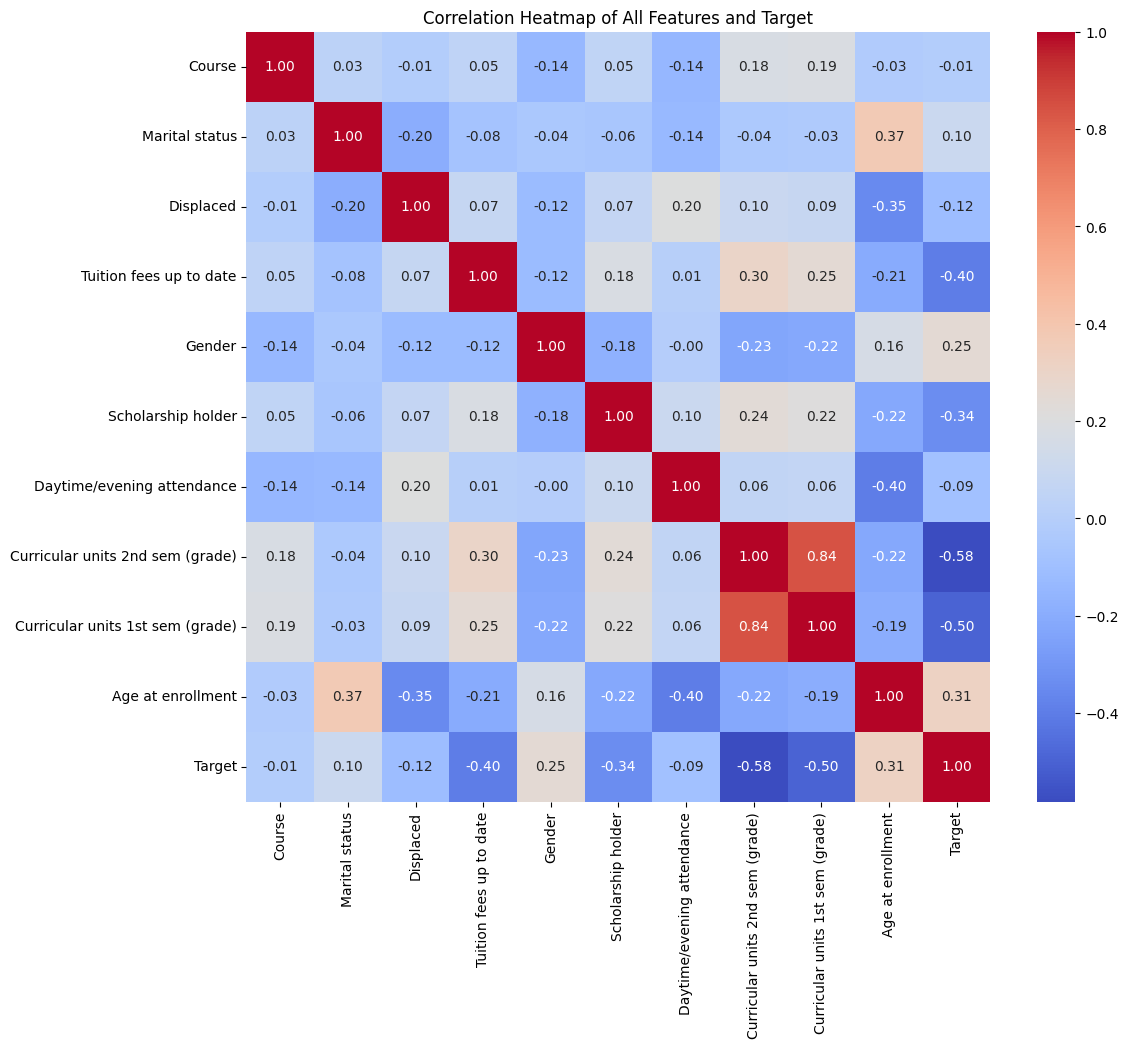

In [30]:
# All feature columns + target
all_cols = processed_data_set.columns

# Compute correlation matrix
corr_matrix = processed_data_set[all_cols].corr()

# Plot heatmap
plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap of All Features and Target")
plt.show()


#Model Design & Implementation & Comparison

Models Selected

1. Logistic Regression
2. Random Forest
3. Decision Tree
4. SVM
5. K-Nearest Neighbors (KNN)
6. XGBoost

##split data for traning

In [31]:
from sklearn.model_selection import train_test_split


# Load preprocessed dataset
processed_data_set = pd.read_csv("processed_data_set.csv")
print("Dataset loaded. Shape:", processed_data_set.shape)

# Separate features and target
X = processed_data_set.drop('Target', axis=1)
y = processed_data_set['Target']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train/Test split done")
print(f"Training samples: {X_train.shape[0]}, Testing samples: {X_test.shape[0]}")


Dataset loaded. Shape: (4114, 11)
Train/Test split done
Training samples: 3291, Testing samples: 823


##Logistic Regression

###libs

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy.stats import loguniform
import numpy as np

###Traine without Hyperparameter Tuning


=== Baseline Logistic Regression ===
Baseline Accuracy: 0.8262

Classification Report (Baseline):
               precision    recall  f1-score   support

           0       0.79      0.89      0.84       412
           1       0.87      0.76      0.81       411

    accuracy                           0.83       823
   macro avg       0.83      0.83      0.83       823
weighted avg       0.83      0.83      0.83       823



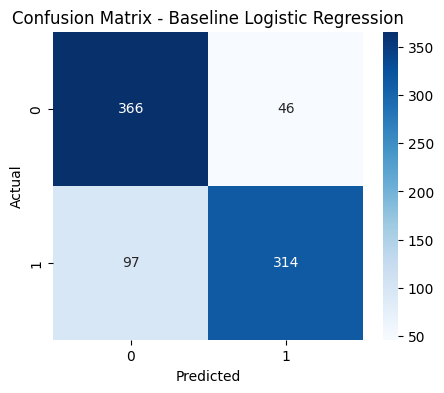

In [33]:
# Baseline Logistic Regression

print("\n=== Baseline Logistic Regression ===")
base_model = LogisticRegression(max_iter=1000, random_state=42)
base_model.fit(X_train, y_train)

# Predictions
y_pred_base = base_model.predict(X_test)

# Evaluation
base_acc = accuracy_score(y_test, y_pred_base)
print(f"Baseline Accuracy: {base_acc:.4f}")
print("\nClassification Report (Baseline):\n", classification_report(y_test, y_pred_base))

# Confusion Matrix
cm_base = confusion_matrix(y_test, y_pred_base)
plt.figure(figsize=(5,4))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Baseline Logistic Regression")
plt.show()

###Hyperparameter Tuning (RandomizedSearchCV)

In [34]:
# Hyperparameter Tuning (RandomizedSearchCV)

param_distributions = {
    'C': loguniform(0.001, 1000),
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced']
}

random_search = RandomizedSearchCV(
    LogisticRegression(max_iter=2000, random_state=42),
    param_distributions=param_distributions,
    n_iter=50,
    cv=10,
    scoring='accuracy',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best Parameters Found:", random_search.best_params_)

# Get best tuned model
best_lr = random_search.best_estimator_

Fitting 10 folds for each of 50 candidates, totalling 500 fits
Best Parameters Found: {'C': np.float64(0.31554382609428006), 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'saga'}


evaluate tuned model

Tuned Accuracy: 0.8287

Classification Report (Tuned):
               precision    recall  f1-score   support

           0       0.79      0.89      0.84       412
           1       0.88      0.76      0.82       411

    accuracy                           0.83       823
   macro avg       0.83      0.83      0.83       823
weighted avg       0.83      0.83      0.83       823



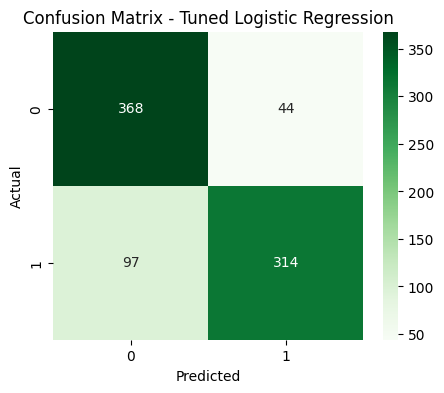

In [35]:
# Get best tuned model to evaluate
y_pred_tuned = best_lr.predict(X_test)

tuned_acc = accuracy_score(y_test, y_pred_tuned)
print(f"Tuned Accuracy: {tuned_acc:.4f}")
print("\nClassification Report (Tuned):\n", classification_report(y_test, y_pred_tuned))

# Confusion Matrix - Tuned
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
plt.figure(figsize=(5,4))
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='Greens', xticklabels=[0,1], yticklabels=[0,1])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Tuned Logistic Regression")
plt.show()

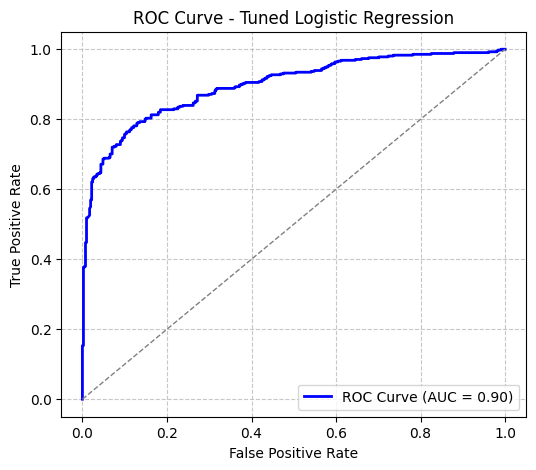

In [36]:
from sklearn.metrics import roc_curve, auc

# Get predicted probabilities (for positive class)
y_prob_tuned = best_lr.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob_tuned)

# Calculate AUC
roc_auc = auc(fpr, tpr)

# Plot ROC Curve
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Tuned Logistic Regression')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

###Cross-Validation (on Tuned Model)

In [37]:
#run cross validation
print("\n=== Cross-Validation on Tuned Model ===")
cv_scores = cross_val_score(best_lr, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1)

#display scores
print("Cross-validation scores:", np.round(cv_scores, 4))
print(f"Mean CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")


=== Cross-Validation on Tuned Model ===
Cross-validation scores: [0.8376 0.8283 0.8237 0.8191 0.8556]
Mean CV Accuracy: 0.8329 ± 0.0129


###test over fitting

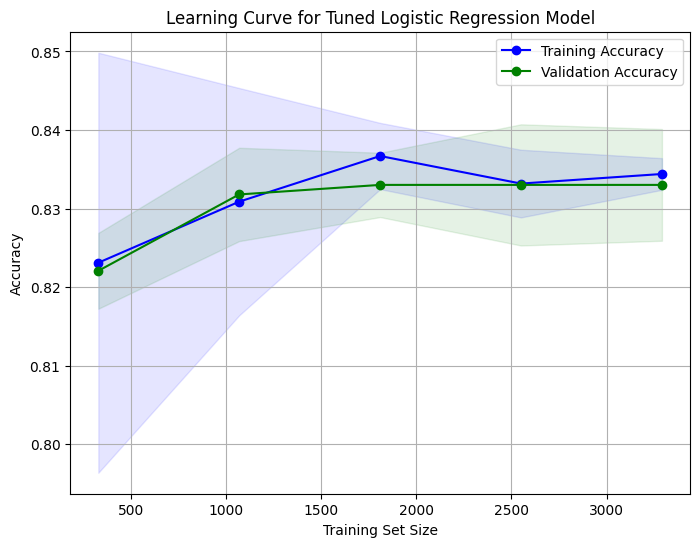

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LogisticRegression

# Logistic Regression with best parameters from RandomizedSearchCV
best_lr = LogisticRegression(
    C=0.31554382609428006,
    class_weight='balanced',
    penalty='l1',
    solver='saga',
    max_iter=2000,
    random_state=42,
    n_jobs=-1
)

# Generate learning curve data
train_sizes, train_scores, test_scores = learning_curve(
    best_lr, X, y,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    shuffle=True,
    random_state=42
)

# Compute means and standard deviations
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(8,6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.plot(train_sizes, test_mean, 'o-', color='green', label='Validation Accuracy')

# Confidence intervals
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='blue', alpha=0.1)
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, color='green', alpha=0.1)

plt.title('Learning Curve for Tuned Logistic Regression Model')
plt.xlabel('Training Set Size')
plt.ylabel('Accuracy')
plt.legend(loc='best')
plt.grid(True)
plt.show()
